# Lab 1 vs Lab 2 — Comparación de modelos

<a href="https://colab.research.google.com/github/lgonperez3-glitch/MLSM-labs/blob/main/Lab2/lab1vslab2_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Este notebook compara en el mismo conjunto de test los tres modelos ganadores: ANN de Lab 1, CNN de Lab 2 Task 1 y VGG16 de Lab 2 Task 2.

**Antes de ejecutar este notebook:** ejecuta hasta el final `lab2_task1_colab.ipynb` y `lab2_task2_colab.ipynb`. Cada uno entrena sus configuraciones, selecciona el ganador por `val_accuracy` y guarda sus mejores pesos en Google Drive. Este notebook carga esos pesos y evalúa los dos ganadores sobre el mismo test utilizado para la ANN.

Los notebooks originales Task 1 y Task 2 no se modifican. La comparación usa las canciones comunes entre el CSV de 30 segundos y las imágenes, conserva el orden y la partición de Lab 2 y genera matrices de confusión y gráficas comparativas.


## 1. Montar Google Drive y configurar rutas

El CSV de características y la carpeta de imágenes deben corresponder al mismo dataset GTZAN.

In [64]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

CSV_PATH = Path("/content/drive/MyDrive/MLSM/Data/features_30_sec.csv")
DATA_DIR = Path("/content/drive/MyDrive/MLSM/Data/images_original")
OUTPUT_DIR = Path("/content/drive/MyDrive/MLSM/Results/lab1vslab2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not CSV_PATH.exists():
    raise FileNotFoundError(f"No se encuentra el CSV: {CSV_PATH}")
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"No se encuentra la carpeta de imágenes: {DATA_DIR}")

print("CSV:", CSV_PATH)
print("Imágenes:", DATA_DIR)
print("Resultados:", OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CSV: /content/drive/MyDrive/MLSM/Data/features_30_sec.csv
Imágenes: /content/drive/MyDrive/MLSM/Data/images_original
Resultados: /content/drive/MyDrive/MLSM/Results/lab1vslab2


## 2. Importaciones y reproducibilidad

Fijamos la semilla utilizada en Lab 2. Esto hace reproducible la partición siempre que el CSV, el orden de sus filas y las etiquetas no cambien.

In [65]:
import json
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_fscore_support
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.4.6
Pandas: 2.2.3


## 3. Cargar y preparar el CSV

La columna `label` contiene el género. El modelo recibe únicamente columnas numéricas. Las columnas de texto, como `filename`, no se utilizan como características.

In [66]:
# Cargar características tabulares.
df = pd.read_csv(CSV_PATH)
print("Dimensiones iniciales del CSV:", df.shape)

required_columns = {"label", "filename"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(
        f"Faltan columnas necesarias en el CSV: {sorted(missing_columns)}. "
        "Se necesita 'filename' para emparejar cada canción con su imagen."
    )

df = df.dropna(subset=["label", "filename"]).copy()
df["label"] = df["label"].astype(str).str.strip()

# Normalización del identificador:
# basename + eliminar extensión + conservar solo letras y números.
# Así, por ejemplo, blues.00001.wav y blues00001.png comparten ID blues00001.
import re
def canonical_song_id(filename):
    stem = Path(str(filename).replace("\\", "/")).name
    stem = Path(stem).stem
    return re.sub(r"[^a-zA-Z0-9]", "", stem).lower()

df["song_id"] = df["filename"].map(canonical_song_id)

if (df["song_id"] == "").any():
    raise ValueError("Hay filenames del CSV que generan un identificador vacío.")
if df["song_id"].duplicated().any():
    duplicates = df.loc[df["song_id"].duplicated(False), ["filename", "song_id"]]
    raise ValueError(
        "Hay identificadores duplicados en el CSV. Revisa estas filas:\\n"
        + duplicates.head(20).to_string(index=False)
    )

# Construir el manifiesto siguiendo EXACTAMENTE el orden de recorrido
# usado en Lab 2 Task 1 y Task 2: géneros ordenados y archivos ordenados.
class_names = sorted(
    folder.name for folder in DATA_DIR.iterdir() if folder.is_dir()
)
valid_extensions = (".png", ".jpg", ".jpeg", ".bmp")
image_rows = []

for label_id, genre in enumerate(class_names):
    genre_folder = DATA_DIR / genre
    for image_path in sorted(genre_folder.iterdir(), key=lambda p: p.name):
        if image_path.is_file() and image_path.suffix.lower() in valid_extensions:
            image_rows.append({
                "image_path": str(image_path),
                "song_id": canonical_song_id(image_path.name),
                "genre": genre,
                "image_label": label_id
            })

image_manifest = pd.DataFrame(image_rows)
if image_manifest.empty:
    raise ValueError(f"No se encontraron imágenes en {DATA_DIR}.")
if (image_manifest["song_id"] == "").any():
    raise ValueError("Hay imágenes que generan un identificador vacío.")
if image_manifest["song_id"].duplicated().any():
    duplicates = image_manifest.loc[
        image_manifest["song_id"].duplicated(False), ["image_path", "song_id"]
    ]
    raise ValueError(
        "Hay identificadores de imagen duplicados:\\n"
        + duplicates.head(20).to_string(index=False)
    )

# Usar únicamente canciones presentes tanto en el CSV de 30 segundos
# como en el conjunto de imágenes. Los elementos sin pareja se omiten.
csv_ids_all = set(df["song_id"])
image_ids_all = set(image_manifest["song_id"])
csv_only_ids = sorted(csv_ids_all - image_ids_all)
image_only_ids = sorted(image_ids_all - csv_ids_all)
common_ids = csv_ids_all & image_ids_all

if not common_ids:
    raise ValueError("No hay canciones en común entre el CSV y las imágenes.")

print("Canciones del CSV sin imagen (omitidas):", len(csv_only_ids), csv_only_ids[:10])
print("Imágenes sin fila en el CSV (omitidas):", len(image_only_ids), image_only_ids[:10])
print("Canciones comunes que se utilizarán:", len(common_ids))

# Filtrar ambos recursos por la intersección, conservando el orden original
# del manifiesto de imágenes para reproducir el split de Lab 2 Task 1/2.
df = df[df["song_id"].isin(common_ids)].copy()
image_manifest = image_manifest[image_manifest["song_id"].isin(common_ids)].copy()
image_manifest = image_manifest.reset_index(drop=True)

csv_ids = set(df["song_id"])
image_ids = set(image_manifest["song_id"])
assert csv_ids == image_ids
assert len(df) == len(image_manifest) == len(common_ids)

# Verificar que el género del CSV coincide con la carpeta de la imagen.
csv_genre_by_id = df.set_index("song_id")["label"]
image_genre_by_id = image_manifest.set_index("song_id")["genre"]
genre_mismatches = [
    song_id for song_id in csv_ids
    if csv_genre_by_id.loc[song_id] != image_genre_by_id.loc[song_id]
]
if genre_mismatches:
    details = [
        (sid, csv_genre_by_id.loc[sid], image_genre_by_id.loc[sid])
        for sid in genre_mismatches[:10]
    ]
    raise ValueError(
        "Hay diferencias de género entre CSV e imágenes. "
        f"Ejemplos (ID, CSV, imagen): {details}"
    )

# X se indexa por ID para poder recuperar las filas en el orden exacto
# de las particiones construidas a partir de las rutas de imagen.
feature_df = df.drop(columns=["label", "filename", "song_id"], errors="ignore")
feature_df = feature_df.select_dtypes(include=[np.number]).copy()
if feature_df.empty:
    raise ValueError("No se encontraron características numéricas en el CSV.")

X_by_id = feature_df.copy()
X_by_id.index = df["song_id"].values

print("Géneros:", class_names)
print("Canciones comunes utilizadas:", len(df))
print("Imágenes encontradas:", len(image_manifest))
print("Correspondencia 1:1 verificada:", len(csv_ids) == len(image_ids))
print("Características numéricas:", X_by_id.shape[1])
display(image_manifest.head())


Dimensiones iniciales del CSV: (1000, 60)
Canciones del CSV sin imagen (omitidas): 1 ['jazz00054']
Imágenes sin fila en el CSV (omitidas): 0 []
Canciones comunes que se utilizarán: 999
Géneros: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
Canciones comunes utilizadas: 999
Imágenes encontradas: 999
Correspondencia 1:1 verificada: True
Características numéricas: 58


,image_path,song_id,genre,image_label
0,/content/drive/MyDrive/MLSM/Data/images_origin...,blues00000,blues,0
1,/content/drive/MyDrive/MLSM/Data/images_origin...,blues00001,blues,0
2,/content/drive/MyDrive/MLSM/Data/images_origin...,blues00002,blues,0
3,/content/drive/MyDrive/MLSM/Data/images_origin...,blues00003,blues,0
4,/content/drive/MyDrive/MLSM/Data/images_origin...,blues00004,blues,0


## 4. Partición 64/16/20 — igual procedimiento que Lab 2

Primero se reserva el 20 % para test. Después, el 20 % del 80 % restante se reserva para validación. Ambas divisiones son estratificadas y usan `random_state=42`.

In [67]:
from sklearn.model_selection import train_test_split

SEED = 42

# Importante: las divisiones se hacen sobre las mismas rutas y etiquetas,
# en el mismo orden, que en los notebooks de Lab 2.
image_paths = image_manifest["image_path"].to_numpy()
image_labels = image_manifest["image_label"].to_numpy()
image_song_ids = image_manifest["song_id"].to_numpy()

dev_paths, test_paths, dev_labels, test_labels, dev_ids, test_ids = train_test_split(
    image_paths,
    image_labels,
    image_song_ids,
    test_size=0.20,
    random_state=SEED,
    stratify=image_labels
)

train_paths, val_paths, train_labels, val_labels, train_ids, val_ids = train_test_split(
    dev_paths,
    dev_labels,
    dev_ids,
    test_size=0.20,
    random_state=SEED,
    stratify=dev_labels
)

# Recuperar las filas del CSV en el orden exacto de cada split de imágenes.
X_train = X_by_id.loc[train_ids].copy()
X_val = X_by_id.loc[val_ids].copy()
X_test = X_by_id.loc[test_ids].copy()

# Usar las etiquetas del manifiesto de imágenes, ya verificadas contra el CSV.
y_train = train_labels.astype(int)
y_val = val_labels.astype(int)
y_test = test_labels.astype(int)

# Comprobaciones explícitas: los IDs son disjuntos y cubren todo el dataset.
assert set(train_ids).isdisjoint(set(val_ids))
assert set(train_ids).isdisjoint(set(test_ids))
assert set(val_ids).isdisjoint(set(test_ids))
assert len(train_ids) + len(val_ids) + len(test_ids) == len(image_manifest)

split_summary = pd.DataFrame({
    "Conjunto": ["Train", "Validation", "Test", "Total"],
    "Canciones": [len(train_ids), len(val_ids), len(test_ids), len(image_song_ids)]
})
split_summary["Porcentaje"] = 100 * split_summary["Canciones"] / len(image_song_ids)
display(split_summary)

print("Partición idéntica al algoritmo de Lab 2:")
print("Train IDs:", len(train_ids))
print("Validation IDs:", len(val_ids))
print("Test IDs:", len(test_ids))
print("Ejemplos de IDs de test:", list(test_ids[:10]))

# Guardar el manifiesto de partición común para trazabilidad.
split_ids = pd.DataFrame({
    "song_id": np.concatenate([train_ids, val_ids, test_ids]),
    "split": (
        ["train"] * len(train_ids)
        + ["validation"] * len(val_ids)
        + ["test"] * len(test_ids)
    )
})
split_ids.to_csv(OUTPUT_DIR / "shared_song_split.csv", index=False)


,Conjunto,Canciones,Porcentaje
0,Train,639,63.963964
1,Validation,160,16.016016
2,Test,200,20.020020
3,Total,999,100.000000


Partición idéntica al algoritmo de Lab 2:
Train IDs: 639
Validation IDs: 160
Test IDs: 200
Ejemplos de IDs de test: ['classical00047', 'blues00086', 'metal00060', 'jazz00088', 'blues00090', 'country00069', 'rock00055', 'country00016', 'hiphop00000', 'jazz00023']


## 5. Definir la ANN ganadora de Lab 1

Se conservan los hiperparámetros seleccionados en Lab 1:
- Capas ocultas: (128, 64)
- `alpha=0.001`
- `learning_rate_init=0.001`
- Optimizador: Adam
- `max_iter=10000`
- Semilla: 42

El preprocesamiento se ajusta dentro del pipeline. Así, la mediana, el escalado y la selección de características se calculan únicamente con el conjunto de entrenamiento y no filtran información de validación/test.

In [68]:
ann_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=f_classif, k="all")),
    ("model", MLPClassifier(
        hidden_layer_sizes=(128, 64),
        solver="adam",
        learning_rate_init=0.001,
        alpha=0.001,
        max_iter=10000,
        random_state=SEED,
        early_stopping=False,
        n_iter_no_change=15,
        tol=1e-3
    ))
])

display(ann_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('variance', VarianceThreshold()), ('scaler', StandardScaler()),
                ('selector', SelectKBest(k='all')),
                ('model',
                 MLPClassifier(alpha=0.001, hidden_layer_sizes=(128, 64),
                               max_iter=10000, n_iter_no_change=15,
                               random_state=42, tol=0.001))])

## 6. Entrenar la ANN

El modelo se entrena solo con train. Validation se reserva para observar generalización; no se utiliza para ajustar pesos porque el MLP conserva `early_stopping=False`, como en la configuración ganadora original.

In [69]:
ann_pipeline.fit(X_train, y_train)
mlp = ann_pipeline.named_steps["model"]

print("Entrenamiento completado.")
print("Iteraciones realizadas:", mlp.n_iter_)
print("Loss final:", mlp.loss_)
print("Convergencia indicada por sklearn:", mlp.n_iter_ < mlp.max_iter)

Entrenamiento completado.
Iteraciones realizadas: 131
Loss final: 0.026272526727304915
Convergencia indicada por sklearn: True


## 7. Curva de pérdida del entrenamiento

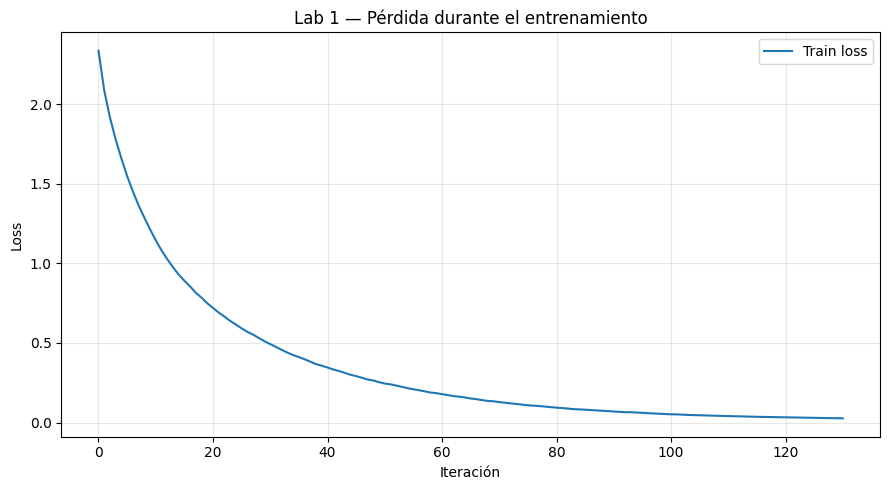

In [70]:
plt.figure(figsize=(9, 5))
plt.plot(mlp.loss_curve_, label="Train loss")
plt.xlabel("Iteración")
plt.ylabel("Loss")
plt.title("Lab 1 — Pérdida durante el entrenamiento")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 8. Métricas de train, validation y test

La métrica principal para la comparación con Lab 2 es la accuracy de test. Train y validation ayudan a diagnosticar sobreajuste.

In [71]:
def evaluate_split(name, features, labels):
    pred = ann_pipeline.predict(features)
    return {
        "Split": name,
        "N": len(labels),
        "Accuracy": accuracy_score(labels, pred),
        "Precision macro": precision_recall_fscore_support(
            labels, pred, average="macro", zero_division=0
        )[0],
        "Recall macro": precision_recall_fscore_support(
            labels, pred, average="macro", zero_division=0
        )[1],
        "F1 macro": precision_recall_fscore_support(
            labels, pred, average="macro", zero_division=0
        )[2],
    }

ann_metrics_df = pd.DataFrame([
    evaluate_split("Train", X_train, y_train),
    evaluate_split("Validation", X_val, y_val),
    evaluate_split("Test", X_test, y_test),
])
display(ann_metrics_df.round(4))

ann_test_accuracy = float(ann_metrics_df.loc[
    ann_metrics_df["Split"] == "Test", "Accuracy"
].iloc[0])

,Split,N,Accuracy,Precision macro,Recall macro,F1 macro
0,Train,639,1.000,1.0000,1.000,1.0000
1,Validation,160,0.725,0.7366,0.725,0.7206
2,Test,200,0.725,0.7431,0.725,0.7265


## 9. Informe de clasificación y matrices de confusión

La diagonal de la matriz representa las predicciones correctas. La matriz normalizada permite comparar el recall de cada género independientemente de cuántas muestras tenga.

              precision    recall  f1-score   support

       blues     0.7333    0.5500    0.6286        20
   classical     1.0000    0.7000    0.8235        20
     country     0.7143    0.7500    0.7317        20
       disco     0.5789    0.5500    0.5641        20
      hiphop     0.7619    0.8000    0.7805        20
        jazz     0.6429    0.9000    0.7500        20
       metal     0.9412    0.8000    0.8649        20
         pop     0.8421    0.8000    0.8205        20
      reggae     0.6250    0.7500    0.6818        20
        rock     0.5909    0.6500    0.6190        20

    accuracy                         0.7250       200
   macro avg     0.7431    0.7250    0.7265       200
weighted avg     0.7431    0.7250    0.7265       200



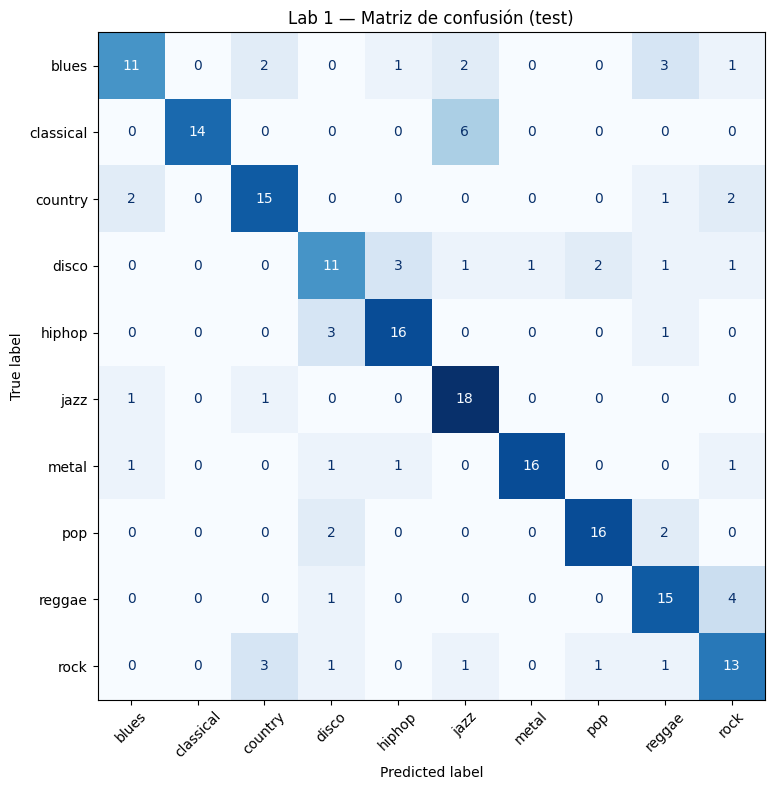

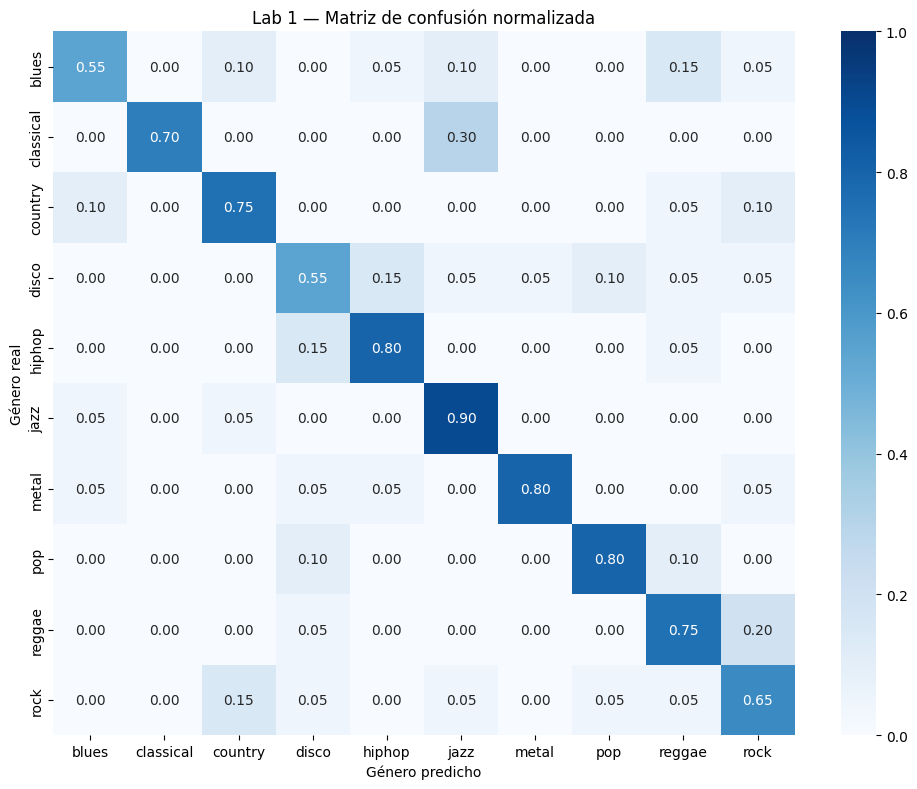

In [72]:
y_test_pred = ann_pipeline.predict(X_test)

print(classification_report(
    y_test, y_test_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0,
    digits=4
))

cm = confusion_matrix(y_test, y_test_pred, labels=np.arange(len(class_names)))
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, values_format="d", colorbar=False
)
ax.set_title("Lab 1 — Matriz de confusión (test)")
plt.tight_layout()
plt.show()

cm_norm = confusion_matrix(
    y_test, y_test_pred,
    labels=np.arange(len(class_names)),
    normalize="true"
)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
    xticklabels=class_names, yticklabels=class_names, ax=ax
)
ax.set_xlabel("Género predicho")
ax.set_ylabel("Género real")
ax.set_title("Lab 1 — Matriz de confusión normalizada")
plt.tight_layout()
plt.show()

## 10. Guardar resultados de Lab 1

Se guardan las métricas, predicciones, nombres de clase y curva de pérdida en Drive para poder consultar los resultados después.

In [73]:
lab1_result = {

    "model": "MLPClassifier",

    "seed": SEED,

    "split": {"train": 0.64, "validation": 0.16, "test": 0.20},

    "n_samples": int(len(X_by_id)),

    "n_train": int(len(X_train)),

    "n_validation": int(len(X_val)),

    "n_test": int(len(X_test)),

    "class_names": [str(x) for x in class_names],

    "test_accuracy": ann_test_accuracy,

    "metrics": ann_metrics_df.to_dict(orient="records"),

    "hyperparameters": {

        "hidden_layer_sizes": [128, 64],

        "alpha": 0.001,

        "learning_rate_init": 0.001,

        "solver": "adam",

        "max_iter": 10000,

        "early_stopping": False,

        "n_iter_no_change": 15,

        "tol": 0.001

    }

}



with open(OUTPUT_DIR / "lab1_metrics.json", "w") as f:

    json.dump(lab1_result, f, indent=2)



np.savez(

    OUTPUT_DIR / "lab1_test_predictions.npz",

    y_true=y_test,

    y_pred=y_test_pred,

    class_names=class_names,
    test_song_ids=test_ids,
    test_image_paths=test_paths

)



pd.DataFrame({

    "iteration": np.arange(1, len(mlp.loss_curve_) + 1),

    "loss": mlp.loss_curve_

}).to_csv(OUTPUT_DIR / "lab1_loss_curve.csv", index=False)



ann_metrics_df.to_csv(OUTPUT_DIR / "lab1_split_metrics.csv", index=False)



print("Resultados guardados en:", OUTPUT_DIR)

Resultados guardados en: /content/drive/MyDrive/MLSM/Results/lab1vslab2


## 11. Cargar y evaluar los modelos ganadores de Task 1 y Task 2

Esta sección **no vuelve a entrenar las búsquedas de hiperparámetros**. Carga los mejores checkpoints guardados por los notebooks originales. Por eso, ejecuta primero ambos notebooks hasta el final y comprueba que existan sus carpetas de resultados en Drive.

Los ganadores se identifican de nuevo leyendo los CSV de experimentos y escogiendo la fila con mayor `val_accuracy`, igual que en Task 1 y Task 2. El test no interviene en esta selección.

La reconstrucción de las arquitecturas conserva sus capas y dimensiones. En VGG16 se usa `weights=None` al reconstruirla porque el checkpoint guardado ya contiene también los pesos congelados preentrenados; después se cargan todos los pesos desde ese checkpoint.

In [62]:
# TensorFlow se utiliza para reconstruir las arquitecturas y ejecutar inferencia.
import tensorflow as tfimport
gcTASK1_RESULTS_DIR = Path("/content/drive/MyDrive/MLSM/Results/Lab 2/task1_results_v3")
TASK2_RESULTS_DIR = Path("/content/drive/MyDrive/MLSM/Results/Lab 2/task2_vgg16_results_v1")
TASK1_CSV = TASK1_RESULTS_DIR / "task1_two_stage_experiments.csv"
TASK2_CSV = TASK2_RESULTS_DIR / "task2_two_stage_experiments.csv"
TASK1_WEIGHTS = TASK1_RESULTS_DIR / "weights"
TASK2_WEIGHTS = TASK2_RESULTS_DIR / "weights"
for required_file in [TASK1_CSV, TASK2_CSV]:
  if not required_file.is_file():
    raise FileNotFoundError(
        f"No existe {required_file}. Ejecuta primero el notebook correspondiente "
        "de Lab 2 hasta completar sus 16 experimentos."
        )task1_experiments = pd.read_csv(TASK1_CSV)
        task2_experiments = pd.read_csv(TASK2_CSV)
        if len(task1_experiments) != 16 or len(task2_experiments) != 16:
          raise ValueError(
              "Se esperaban 16 experimentos completados en cada tarea. "
              f"Task 1: {len(task1_experiments)}; Task 2: {len(task2_experiments)}."
              )
  # Selección idéntica a la de los notebooks originales: mayor accuracy de validación.task1_winner = task1_experiments.sort_values(    ["val_accuracy", "name"], ascending=[False, True]).iloc[0]task2_winner = task2_experiments.sort_values(    ["val_accuracy", "name"], ascending=[False, True]).iloc[0]task1_name = str(task1_winner["name"])task2_name = str(task2_winner["name"])task1_weights_file = TASK1_WEIGHTS / f"{task1_name}.weights.h5"task2_weights_file = TASK2_WEIGHTS / f"{task2_name}.weights.h5"for weights_file in [task1_weights_file, task2_weights_file]:    if not weights_file.is_file():        raise FileNotFoundError(            f"No se encuentra el checkpoint {weights_file}. "            "Vuelve a ejecutar el notebook de la tarea correspondiente."        )print("Ganador Task 1 (CNN):", task1_name)print("Accuracy de validación Task 1:", round(float(task1_winner["val_accuracy"]), 4))print("Checkpoint Task 1:", task1_weights_file)print()print("Ganador Task 2 (VGG16):", task2_name)print("Accuracy de validación Task 2:", round(float(task2_winner["val_accuracy"]), 4))print("Checkpoint Task 2:", task2_weights_file)# Recuperar los hiperparámetros guardados para reconstruir cada arquitectura.def task1_config_from_row(row):    return {        "filters": tuple(map(int, str(row["filters"]).split("-"))),        "kernel": tuple(map(int, str(row["kernel"]).split("x"))),        "dropout": float(row["dropout"]),        "augment": str(row["augment"]).lower() == "true",        "lr": float(row["lr"]),        "size": (int(row["img_h"]), int(row["img_w"])),    }def task2_config_from_row(row):    return {        "filters": tuple(map(int, str(row["filters"]).split("-"))),        "vgg_blocks": int(row["vgg_blocks"]),        "kernel": tuple(map(int, str(row["kernel"]).split("x"))),        "dropout": float(row["dropout"]),        "augment": str(row["augment"]).lower() == "true",        "lr": float(row["lr"]),        "size": (int(row["img_h"]), int(row["img_w"])),    }task1_config = task1_config_from_row(task1_winner)task2_config = task2_config_from_row(task2_winner)# Arquitectura CNN de Task 1. Se omite compile(): para evaluar pesos no hace falta# reconstruir el optimizador, pero sí se mantienen exactamente las capas del modelo.def build_task1_cnn(num_classes, config):    height, width = config["size"]    inputs = tf.keras.Input(shape=(height, width, 3))    x = inputs    if config["augment"]:        x = tf.keras.layers.RandomTranslation(            height_factor=0.0, width_factor=0.05        )(x)        x = tf.keras.layers.RandomZoom(            height_factor=0.0, width_factor=0.1        )(x)        x = tf.keras.layers.RandomContrast(0.1)(x)    x = tf.keras.layers.Rescaling(1.0 / 255.0)(x)    for n_filters in config["filters"]:        x = tf.keras.layers.Conv2D(            filters=n_filters, kernel_size=config["kernel"],            padding="same", use_bias=False        )(x)        x = tf.keras.layers.BatchNormalization()(x)        x = tf.keras.layers.Activation("relu")(x)        x = tf.keras.layers.MaxPooling2D(pool_size=2)(x)    x = tf.keras.layers.GlobalAveragePooling2D()(x)    x = tf.keras.layers.Dense(128, activation="relu")(x)    if config["dropout"] > 0:        x = tf.keras.layers.Dropout(config["dropout"])(x)    outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)    return tf.keras.Model(inputs=inputs, outputs=outputs)# Arquitectura VGG16 de Task 2. weights=None evita descargar ImageNet:# el checkpoint contiene tanto los pesos preentrenados como la cabeza entrenada.def build_task2_vgg16(num_classes, config):    height, width = config["size"]    inputs = tf.keras.Input(shape=(height, width, 3))    x = inputs    if config["augment"]:        x = tf.keras.layers.RandomTranslation(0.0, 0.05)(x)        x = tf.keras.layers.RandomZoom(0.0, 0.1)(x)        x = tf.keras.layers.RandomContrast(0.1)(x)    x = tf.keras.applications.vgg16.preprocess_input(x)    full_vgg = tf.keras.applications.VGG16(        include_top=False, weights=None, input_shape=(height, width, 3)    )    full_vgg.trainable = False    blocks = config["vgg_blocks"]    feature_extractor = tf.keras.Model(        full_vgg.input,        full_vgg.get_layer(f"block{blocks}_pool").output,        name=f"vgg16_first_{blocks}_blocks"    )    x = feature_extractor(x, training=False)    x = tf.keras.layers.Conv2D(        128, config["kernel"], padding="same",        activation="relu", name="additional_conv"    )(x)    x = tf.keras.layers.GlobalAveragePooling2D()(x)    x = tf.keras.layers.Dense(128, activation="relu")(x)    if config["dropout"] > 0:        x = tf.keras.layers.Dropout(config["dropout"])(x)    outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)    return tf.keras.Model(inputs, outputs)# Dataset de evaluación sin barajado ni aumento de datos.# Mantiene el orden exacto de test_paths, necesario para alinear predicciones e IDs.def make_comparison_dataset(file_paths, file_labels, size):    dataset = tf.data.Dataset.from_tensor_slices((file_paths, file_labels))    def decode_and_resize(path, label):        image_bytes = tf.io.read_file(path)        image = tf.image.decode_image(            image_bytes, channels=3, expand_animations=False        )        image.set_shape([None, None, 3])        image = tf.image.resize(image, size)        return image, label    return dataset.map(        decode_and_resize, num_parallel_calls=tf.data.AUTOTUNE    ).batch(32).prefetch(tf.data.AUTOTUNE)# Verificar que la ANN y los dos modelos de imagen se evalúan sobre las mismas# etiquetas y el mismo número de canciones.assert np.array_equal(y_test, test_labels)assert len(test_paths) == len(test_ids) == len(y_test)# Task 1: cargar el checkpoint ganador y obtener probabilidades en test.tf.keras.backend.clear_session()task1_model = build_task1_cnn(len(class_names), task1_config)task1_model.load_weights(str(task1_weights_file))task1_test_ds = make_comparison_dataset(    test_paths, test_labels, task1_config["size"])task1_probabilities = task1_model.predict(task1_test_ds, verbose=0)task1_predictions = np.argmax(task1_probabilities, axis=1)del task1_model, task1_test_dstf.keras.backend.clear_session()gc.collect()# Task 2: cargar el checkpoint ganador de VGG16 y obtener probabilidades en test.task2_model = build_task2_vgg16(len(class_names), task2_config)task2_model.load_weights(str(task2_weights_file))task2_test_ds = make_comparison_dataset(    test_paths, test_labels, task2_config["size"])task2_probabilities = task2_model.predict(task2_test_ds, verbose=0)task2_predictions = np.argmax(task2_probabilities, axis=1)del task2_model, task2_test_dstf.keras.backend.clear_session()gc.collect()# La ANN ya se ha evaluado en las secciones anteriores.predictions_by_model = {    "Lab 1 — ANN": np.asarray(y_test_pred),    "Lab 2 Task 1 — CNN": np.asarray(task1_predictions),    "Lab 2 Task 2 — VGG16": np.asarray(task2_predictions),}y_true_comparison = np.asarray(y_test)for model_name, predictions in predictions_by_model.items():    if len(predictions) != len(y_true_comparison):        raise ValueError(            f"{model_name}: número de predicciones distinto del test."        )print("Evaluación completada para los tres modelos.")print("Canciones de test compartidas:", len(y_true_comparison))print("Orden de clases:", class_names)

## 12. Matrices de confusión de los tres modelos

Cada modelo se evalúa con las mismas canciones de test y el mismo orden de clases. Para cada uno se muestran:

- **Matriz absoluta:** número de canciones de cada género clasificadas en cada clase.
- **Matriz normalizada:** proporción por género real; permite comparar los errores aunque las clases tengan tamaños distintos.

In [63]:
# Calcular métricas y matrices con un orden de clases común.
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

labels_order = np.arange(len(class_names))
comparison_rows = []
confusion_matrices = {}
normalized_matrices = {}
per_class_f1 = {}

for model_name, predictions in predictions_by_model.items():
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true_comparison, predictions, labels=labels_order,
        average="macro", zero_division=0
    )
    comparison_rows.append({
        "Modelo": model_name,
        "Accuracy test": accuracy_score(y_true_comparison, predictions),
        "Precision macro": precision_macro,
        "Recall macro": recall_macro,
        "F1 macro": f1_macro,
        "Canciones test": len(y_true_comparison),
    })

    confusion_matrices[model_name] = confusion_matrix(
        y_true_comparison, predictions, labels=labels_order
    )
    normalized_matrices[model_name] = confusion_matrix(
        y_true_comparison, predictions, labels=labels_order,
        normalize="true"
    )
    _, _, class_f1, _ = precision_recall_fscore_support(
        y_true_comparison, predictions, labels=labels_order,
        average=None, zero_division=0
    )
    per_class_f1[model_name] = class_f1

    print(f"\nInforme de clasificación — {model_name}")
    print(classification_report(
        y_true_comparison, predictions,
        labels=labels_order, target_names=class_names,
        zero_division=0, digits=4
    ))

    # Matriz de confusión absoluta.
    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(
        confusion_matrices[model_name], display_labels=class_names
    ).plot(
        ax=ax, xticks_rotation=45, colorbar=False, values_format="d"
    )
    ax.set_title(f"Matriz de confusión — {model_name}")
    ax.set_xlabel("Género predicho")
    ax.set_ylabel("Género real")
    plt.tight_layout()
    plt.show()

    # Matriz de confusión normalizada por género real.
    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(
        normalized_matrices[model_name], display_labels=class_names
    ).plot(
        ax=ax, xticks_rotation=45, colorbar=True, values_format=".2f"
    )
    ax.set_title(f"Matriz de confusión normalizada — {model_name}")
    ax.set_xlabel("Género predicho")
    ax.set_ylabel("Género real")
    plt.tight_layout()
    plt.show()

comparison_metrics_df = pd.DataFrame(comparison_rows)
display(comparison_metrics_df.round(4))

# Guardar métricas, predicciones e IDs para poder reproducir el análisis.
comparison_metrics_df.to_csv(
    OUTPUT_DIR / "three_model_comparison_metrics.csv", index=False
)
np.savez(
    OUTPUT_DIR / "three_model_test_predictions.npz",
    y_true=y_true_comparison,
    ann=predictions_by_model["Lab 1 — ANN"],
    task1_cnn=predictions_by_model["Lab 2 Task 1 — CNN"],
    task2_vgg16=predictions_by_model["Lab 2 Task 2 — VGG16"],
    test_song_ids=test_ids,
    class_names=class_names
)

for model_name, matrix in confusion_matrices.items():
    safe_name = (
        model_name.lower().replace(" ", "_").replace("—", "").replace("-", "")
    )
    pd.DataFrame(
        matrix, index=class_names, columns=class_names
    ).to_csv(OUTPUT_DIR / f"confusion_{safe_name}.csv")
    pd.DataFrame(
        normalized_matrices[model_name],
        index=class_names, columns=class_names
    ).to_csv(OUTPUT_DIR / f"confusion_normalized_{safe_name}.csv")

print("Métricas, predicciones y matrices guardadas en:", OUTPUT_DIR)


NameError: name 'predictions_by_model' is not defined

## 13. Gráficas comparativas de los tres modelos

La primera gráfica compara accuracy, precision macro, recall macro y F1 macro. La segunda compara el F1 de cada género, para detectar en qué estilos musicales destaca o falla cada arquitectura.

In [ ]:
# Comparación global de métricas de test.
metric_columns = [
    "Accuracy test", "Precision macro", "Recall macro", "F1 macro"
]
plot_metrics = comparison_metrics_df.set_index("Modelo")[metric_columns]

ax = plot_metrics.plot(
    kind="bar", figsize=(11, 6), ylim=(0, 1), rot=0
)
ax.set_ylabel("Puntuación")
ax.set_xlabel("")
ax.set_title("Comparación de los tres modelos en test")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Comparación por género: F1-score de cada clase.
class_f1_df = pd.DataFrame(
    per_class_f1, index=class_names
)
ax = class_f1_df.plot(
    kind="bar", figsize=(13, 6), ylim=(0, 1), rot=35
)
ax.set_ylabel("F1-score")
ax.set_xlabel("Género musical")
ax.set_title("F1-score por género y modelo")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Modelo")
plt.tight_layout()
plt.show()

# Guardar también la tabla de F1 por género.
class_f1_df.to_csv(OUTPUT_DIR / "three_model_f1_by_genre.csv")
display(class_f1_df.round(4))

# Resumen del ganador por accuracy de test (solo descriptivo; no cambia la selección).
best_test_row = comparison_metrics_df.loc[
    comparison_metrics_df["Accuracy test"].idxmax()
]
print(
    "Mayor accuracy observada en test:",
    best_test_row["Modelo"],
    f"({best_test_row['Accuracy test']:.4f})"
)
print(
    "Este resultado describe el test; no se debe reutilizar para reajustar "
    "hiperparámetros ni seleccionar modelos."
)


## 14. Interpretación y límites

- La comparación utiliza el mismo conjunto de test, con los mismos IDs, etiquetas y orden de clases para los tres modelos.
- La ANN recibe características tabulares; la CNN y VGG16 reciben imágenes. Sus arquitecturas y entradas son diferentes, aunque la evaluación se realiza sobre las mismas canciones.
- Los ganadores de Task 1 y Task 2 se seleccionan por accuracy de validación. La accuracy de test se utiliza únicamente para la evaluación final.
- La matriz normalizada facilita comparar el recall por género; la gráfica de F1 por género muestra qué estilos resultan más difíciles para cada modelo.
- Las búsquedas de Task 1 y Task 2 deben haberse ejecutado con la misma versión del dataset, el mismo orden de archivos y la semilla 42. Si cambias el dataset o las particiones, vuelve a ejecutar las tareas y después este notebook.

**Archivos de salida:** `MyDrive/MLSM/Results/lab1vslab2/` contiene las métricas, predicciones, matrices de confusión y tablas de comparación.